# **Preparing Dependancies**

In [1]:
!pip install torch

In [2]:
# Install / upgrade the libraries (Colab T4 runtime).
!pip install -q --upgrade diffusers transformers accelerate safetensors scipy

# --- Guard against the "stale module" error ------------------------------------------------------
# If diffusers was already imported in THIS kernel before the upgrade, Python keeps the OLD code in memory
# while the NEW files sit on disk. Lazy imports (e.g. the SDXL pipeline, loaded much later) then mix the two
# versions and crash with "cannot import name ...". The clean fix is a one-time runtime restart.
import os, sys
import importlib.metadata as md

if "diffusers" in sys.modules and sys.modules["diffusers"].__version__ != md.version("diffusers"):
    print(f"diffusers in memory = {sys.modules['diffusers'].__version__} | on disk = {md.version('diffusers')}")
    print("Restarting the runtime now. After it restarts, just run the notebook again from the top.")
    os.kill(os.getpid(), 9)      # Colab restarts the kernel automatically

print("diffusers", md.version("diffusers"), "| transformers", md.version("transformers"))

diffusers 0.42.1 | transformers 5.22.1


In [3]:

import gc
import os
import numpy as np
import torch
from PIL import Image, ImageFilter, ImageDraw
import matplotlib.pyplot as plt

assert torch.cuda.is_available(), "Enable a GPU: Runtime > Change runtime type > T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16          # half precision: ~2x less VRAM and faster on a T4
os.makedirs("outputs", exist_ok=True)


def clear_memory():
    """Release Python objects, then hand cached CUDA blocks back to the driver.
    Call this after `del pipe` - deleting alone does not free VRAM while references remain."""
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()


def show_images(images, titles=None, figsize_per_img=4, cols=None, save_as=None):
    """Display a list of PIL images side by side with optional titles."""
    cols = cols or len(images)
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(figsize_per_img * cols, figsize_per_img * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for i, img in enumerate(images):
        axes[i].imshow(img)
        if titles:
            axes[i].set_title(titles[i], fontsize=10)
    plt.tight_layout()
    if save_as:
        plt.savefig(f"outputs/{save_as}", dpi=120, bbox_inches="tight")
    plt.show()

In [4]:
# ---- Shared settings so every section is comparable ----
SEED = 222
PROMPT = ("A cartoon astronaut standing on the Moon, realistic textured lunar surface, Earth in the background, starry sky, soft natural lighting, clean illustration style, slightly detailed background, soft natural lighting, visible shadow on the ground")
NEGATIVE_PROMPT = ("photo, photorealistic, 3d render, blurry, low quality, deformed, bad anatomy, "
                   "extra limbs, text, watermark, cropped")

# **Kriteria 1: Melakukan Image Generation dari Teks (Text-to-Image)**

## **Load Base Pipeline Model**

In [5]:
import sys
# Mock torchao.quantization.FqnToConfig to prevent import errors in diffusers
try:
    import torchao.quantization
    if not hasattr(torchao.quantization, 'FqnToConfig'):
        torchao.quantization.FqnToConfig = None
except ImportError:
    pass



from diffusers import StableDiffusionPipeline

BASE_MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL_ID,
    torch_dtype=DTYPE,        # fp16 weights
    use_safetensors=True,
)
pipe = pipe.to(DEVICE)
pipe.enable_attention_slicing()   # compute attention in slices: lower peak VRAM, tiny speed cost
pipe.set_progress_bar_config(disable=False)

# Keep the original scheduler config so we can restore it after the scheduler experiment.
DEFAULT_SCHEDULER_CONFIG = pipe.scheduler.config
print("Base pipeline loaded on", DEVICE, "| scheduler:", pipe.scheduler.__class__.__name__)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Base pipeline loaded on cuda | scheduler: PNDMScheduler


## **Generate Image (generate_simple_image)**
Pada bagian ini, Anda akan menghasilkan gambar dari teks. Sasarannya adalah menghasilkan gambar yang mendekati gambar contoh di bawah ini, yaitu seorang astronaut di permukaan bulan dengan gaya digital art 2D. Perhatikan empat elemen visual utama berikut:

*   Astronaut berbaju putih
*   Permukaan bulan
*   Bumi di langit
*   Gaya ilustrasi 2D

(bukan foto realistis).

Gunakan Seed bernilai 222 dan negative prompt yang telah ditetapkan. Pastikan prompt yang Anda gunakan sama pada kedua fungsi agar hasilnya dapat dibandingkan secara objektif.

### **Referensi output:**

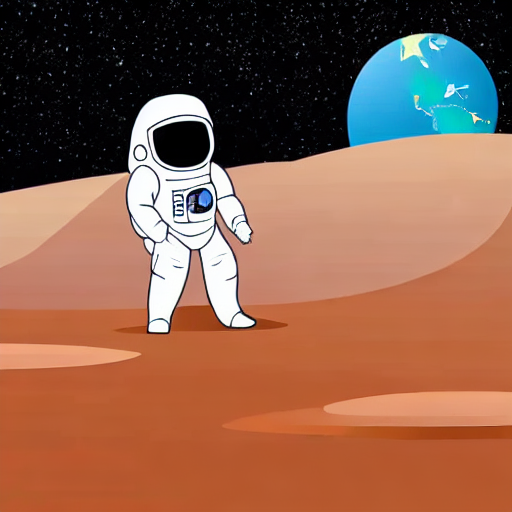

  0%|          | 0/50 [00:00<?, ?it/s]

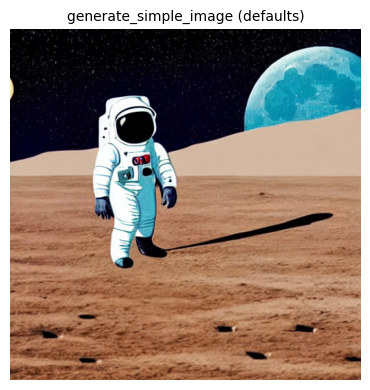

In [6]:
def generate_simple_image(prompt, negative_prompt, seed=SEED):
    """Baseline generation: every hyperparameter is left at the pipeline default
    (50 steps, guidance 7.5, 512x512). Only the seed is fixed for reproducibility."""
    generator = torch.Generator(device=DEVICE).manual_seed(seed)   # same seed -> same starting noise
    with torch.inference_mode():
        result = pipe(prompt=prompt,
                      negative_prompt=negative_prompt,
                      generator=generator,
        )
    return result.images[0]


image_simple = generate_simple_image(PROMPT, NEGATIVE_PROMPT, seed=SEED)
image_simple.save("outputs/01_simple.png")
show_images([image_simple], ["generate_simple_image (defaults)"])

## **Generate Image with Hyperparameter Configuration (generate_advanced_image)**
Tetap gunakan Seed bernilai 222 dan negative prompt yang telah ditetapkan. Pastikan prompt yang Anda gunakan sama pada kedua fungsi agar hasilnya dapat dibandingkan secara objektif.

### **Referensi Output:**

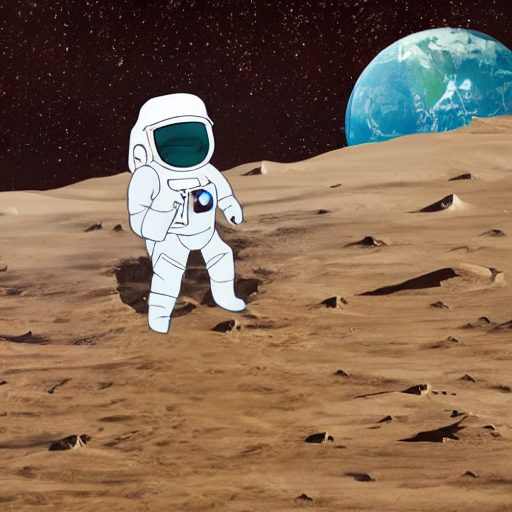

  0%|          | 0/30 [00:00<?, ?it/s]

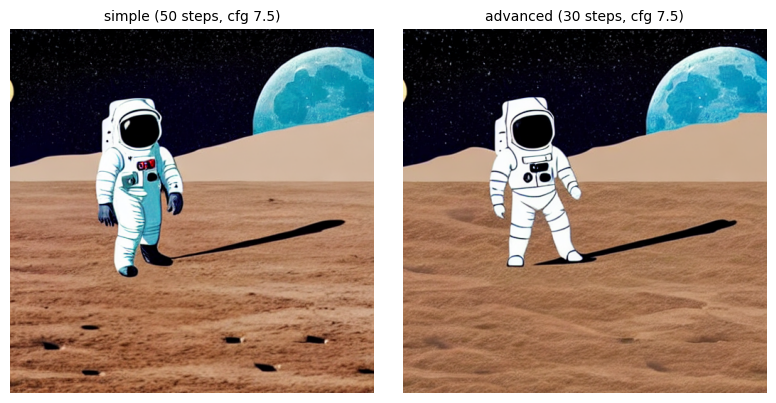

In [7]:
def generate_advanced_image(prompt, negative_prompt, seed=SEED,
                            steps=30, guidance_scale=7.5,
                            width=512, height=512, num_images=1):
    """Same prompt + seed as the simple version, but with explicit hyperparameters:
    - steps: number of denoising iterations
    - guidance_scale (CFG): how strongly the image is pushed toward the prompt
    - width/height: must be multiples of 8 (the VAE downsamples by 8)"""
    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    with torch.inference_mode():
        result = pipe(
            prompt=prompt,
            negative_prompt=negative_prompt,
            num_inference_steps=steps,
            guidance_scale=guidance_scale,
            width=width,
            height=height,
            num_images_per_prompt=num_images,
            generator=generator,
        )
    return result.images if num_images > 1 else result.images[0]


image_advanced = generate_advanced_image(PROMPT, NEGATIVE_PROMPT, seed=SEED,
                                         steps=30, guidance_scale=7.5)
image_advanced.save("outputs/02_advanced.png")
show_images([image_simple, image_advanced], ["simple (50 steps, cfg 7.5)", "advanced (30 steps, cfg 7.5)"])

## **Guidance Scale Comparison**

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

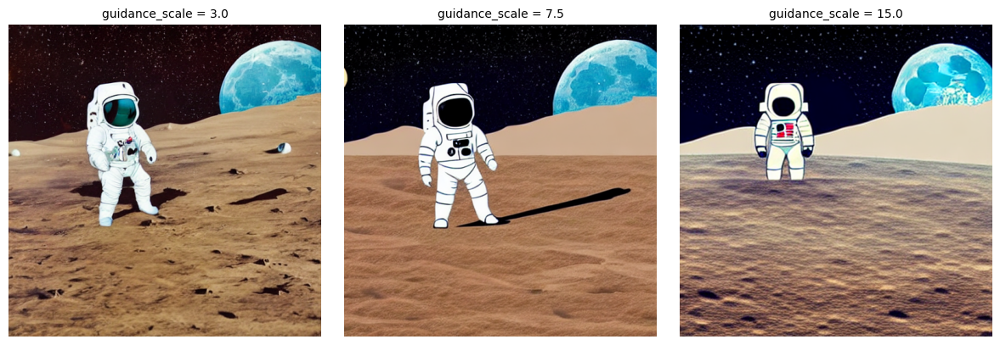

In [8]:
# Only guidance_scale changes; seed, prompt and steps are identical, so differences come from CFG alone.
cfg_values = [3.0, 7.5, 15.0]
cfg_images = [generate_advanced_image(PROMPT, NEGATIVE_PROMPT, seed=SEED, steps=30, guidance_scale=g)
              for g in cfg_values]

show_images(cfg_images, [f"guidance_scale = {g}" for g in cfg_values], save_as="03_guidance_comparison.png")

### **Guidance Scale Explanation:**

*   **Gambar dengan "Scale" Rendah:**   
Gambar dengan guidance scale rendah berarti model diberikan kebebasan berkreasi yang besar sehingga menghasilkan variasi visual yang sangat kaya, namun tingkat kesesuaiannya dengan prompt cukup longgar dan sering kali mengabaikan elemen spesifik yang saya minta.

*   **Gambar dengan "Scale" Tinggi:**   
penggunaan guidance scale yang tinggi (15.0) akan memaksa model untuk mematuhi prompt secara mutlak, yang secara drastis mengorbankan kebebasan dan variasi visual AI. Selain itu warna disini juga terlalu kontras atau oversaturated (burn-out effect), serta anatomi yang terdistorsi.

jika dibandingkan dengan scale yang cukup, gambar menunjukkan tingkat detail yang tajam, proporsi yang realistis, dan mematuhi prompt secara akurat tanpa mengorbankan kualitas komposisi maupun harmoni warna.

## **Inference Steps Comparison**

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

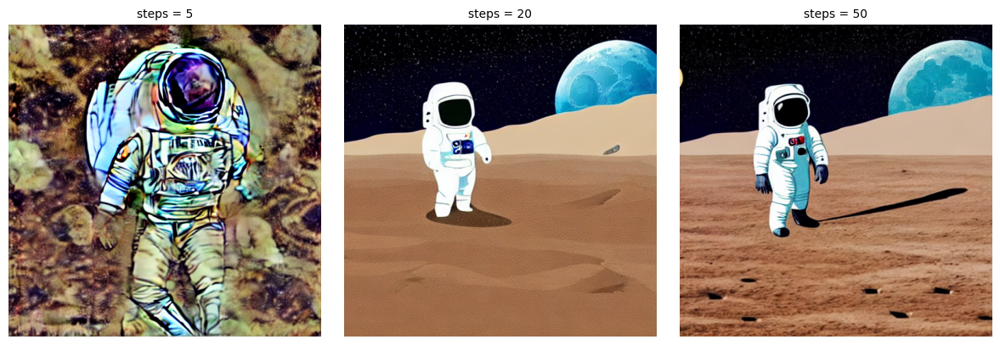

In [9]:
# Only num_inference_steps changes; guidance and seed are fixed.
step_values = [5, 20, 50]
step_images = [generate_advanced_image(PROMPT, NEGATIVE_PROMPT, seed=SEED, steps=s, guidance_scale=7.5)
               for s in step_values]

show_images(step_images, [f"steps = {s}" for s in step_values], save_as="04_steps_comparison.png")

### **Inference Step Explanation:**

*   **Gambar dengan "Step" Rendah:**  
Pada inference steps yang rendah (5 langkah), proses denoising ini dipaksa berhenti sebelum benar-benar tuntas, sehingga karakteristik gambar yang dihasilkan disini sangat buram, kurang tajam, dan miskin detail. Karena model tidak memiliki cukup waktu untuk merekonstruksi dan merapikan setiap piksel, probabilitas munculnya noise dan artefak visual sangatlah tinggi; Disini kita melihat objek yang tampak seperti coretan kasar yang belum selesai, bentuk yang mencair, dan elemen komposisi yang saling tumpang tindih secara tidak logis.
*   **Gambar dengan "Step" Tinggi:**  
Sebaliknya, ketika Anda menaikkan inference steps ke tingkat yang tinggi (50 langkah), perbedaan visual yang terlihat dibandingkan step rendah sangatlah signifikan. Pada tahap ini, gambar menampilkan tingkat detail yang presisi dan ketajaman tepi yang optimal karena model memiliki iterasi yang cukup untuk menyempurnakan struktur terkecil. Hasil akhirnya juga menawarkan kehalusan visual yang luar biasa tanpa jejak noise, serta stabilitas visual yang sangat solid, di mana setiap anatomi, tekstur, dan pencahayaan terbentuk secara utuh, kohesif, dan bebas dari distorsi yang biasa terjadi pada iterasi yang terburu-buru.

## **Batch Inference from One Prompt**

  0%|          | 0/30 [00:00<?, ?it/s]

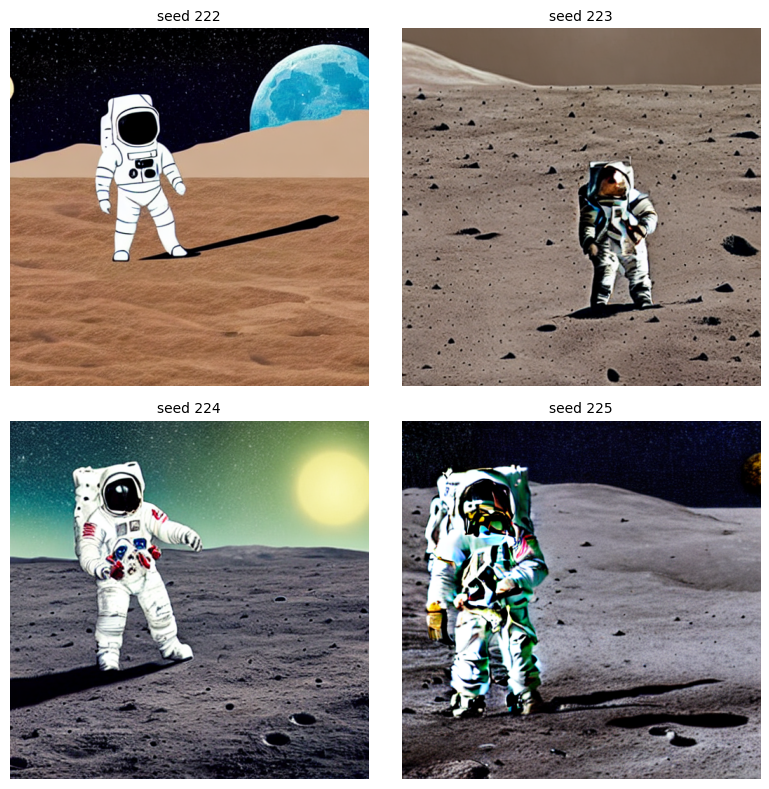

In [10]:
# Batch inference: several variations of ONE prompt in a single call.
# A *list* of generators gives each image in the batch its own reproducible seed
# (a single generator would also work, but then the images cannot be regenerated individually).
BATCH_SIZE = 4
batch_seeds = [SEED + i for i in range(BATCH_SIZE)]
generators = [torch.Generator(device=DEVICE).manual_seed(s) for s in batch_seeds]

with torch.inference_mode():
    batch_result = pipe(
        prompt=PROMPT,
        negative_prompt=NEGATIVE_PROMPT,
        num_inference_steps=30,
        guidance_scale=7.5,
        num_images_per_prompt=BATCH_SIZE,   # latents tensor has shape [BATCH_SIZE, 4, 64, 64]
        generator=generators,
    )

batch_images = batch_result.images
show_images(batch_images, [f"seed {s}" for s in batch_seeds], cols=2, save_as="05_batch.png")

## **Load Scheduler**

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

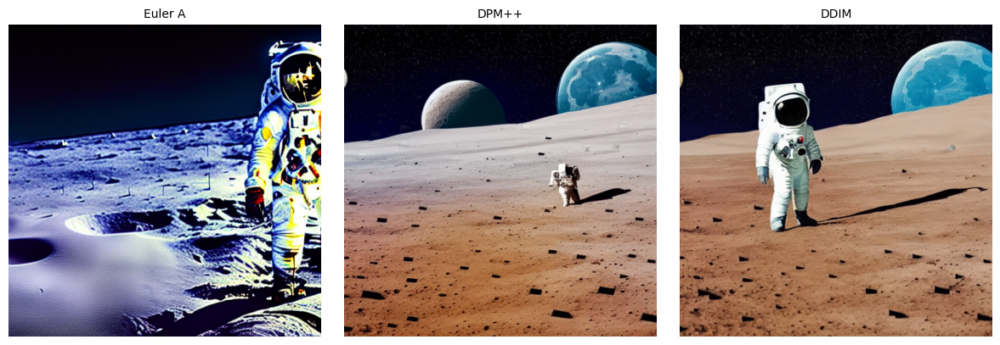

In [11]:
from diffusers import (
    PNDMScheduler,                     # SD 1.5 default
    EulerAncestralDiscreteScheduler,   # "Euler A"
    DPMSolverMultistepScheduler,       # "DPM++ 2M"
    DDIMScheduler,
)

# Every scheduler is built from the SAME config as the default one, so only the sampling algorithm changes.
schedulers = {
    "Euler A": EulerAncestralDiscreteScheduler.from_config(DEFAULT_SCHEDULER_CONFIG),
    "DPM++":   DPMSolverMultistepScheduler.from_config(DEFAULT_SCHEDULER_CONFIG, algorithm_type="dpmsolver++"),
    "DDIM":    DDIMScheduler.from_config(DEFAULT_SCHEDULER_CONFIG),
}

scheduler_images = []
for name, sched in schedulers.items():
    pipe.scheduler = sched                      # hot-swap the sampler, the model weights are untouched
    img = generate_advanced_image(PROMPT, NEGATIVE_PROMPT, seed=SEED, steps=25, guidance_scale=7.5)
    scheduler_images.append(img)

show_images(scheduler_images, list(schedulers.keys()), save_as="06_scheduler_comparison.png")

# Restore the default scheduler so later cells are not affected.
pipe.scheduler = PNDMScheduler.from_config(DEFAULT_SCHEDULER_CONFIG)

### **Scheduler Comparation:**

*   **Gambar dengan "Euler A Scheduler":**  
Karakteristik gambar yang dihasilkan oleh Euler A cenderung lebih artistik, lembut, dan memiliki estetika dreamy atau menyerupai lukisan, di mana detail kecil tidak terlalu tajam. Hal ini terjadi karena Euler A merupakan scheduler stokastik; ia sengaja menyuntikkan sedikit noise (unsur acak) kembali ke dalam gambar pada setiap langkah denoising. Akibat suntikan noise ini, proses pembentukan gambar tidak pernah benar-benar konvergen atau "mengunci" secara absolut. Itulah sebabnya, jika saya terus menambah jumlah inference steps pada Euler A, komposisi dan bentuk objek akan terus bergeser dan berubah alih-alih menjadi lebih tajam.
*   **Gambar dengan "DPM++ Scheduler":**  
Sebaliknya, gambar yang dihasilkan dengan DPM++ memiliki karakteristik yang sangat tajam, tekstur mikro yang presisi. Kualitas seperti ini bisa dicapai karena DPM++ menggunakan algoritma pemecah persamaan diferensial matematika tingkat lanjut untuk menemukan rute paling optimal dalam menghapus noise. Scheduler ini sangat presisi dan cepat mencapai titik konvergen (stabil); begitu bentuk dasar terbentuk di step awal, penambahan steps berikutnya hanya akan memoles dan mempertegas detail yang sudah ada tanpa merombak keseluruhan komposisi gambar.
*   **Gambar dengan "DDIM Scheduler":**  
Sementara itu, DDIM (Denoising Diffusion Implicit Models) menawarkan karakteristik gambar yang sangat smooth, sedikit lebih soft dibandingkan DPM++, namun memiliki tingkat konsistensi dan stabilitas struktural yang luar biasa. Alasan di balik karakteristik ini adalah arsitektur matematika DDIM yang menggunakan proses implisit non-Markovian, yang berarti proses pembersihan noise-nya sepenuhnya deterministik tanpa ada penambahan elemen acak sama sekali di tengah jalan.

# **Kriteria 2: Menyempurnakan Gambar Melalui Image-to-Image**

## **Inpainting**

**Perhatian:** Gunakan gambar hasil `generate_advanced_image()` atau `generate_simple_image()` sebagai `image`, bukan gambar baru.

Hasil Inpainting yang Anda lakukan perlu dibuat semirip mungkin atau setidaknya menambahkan broken satelite seperti pada Gambar yang ditetapkan berikut ini. (Gunakan Seed bernilai 9)

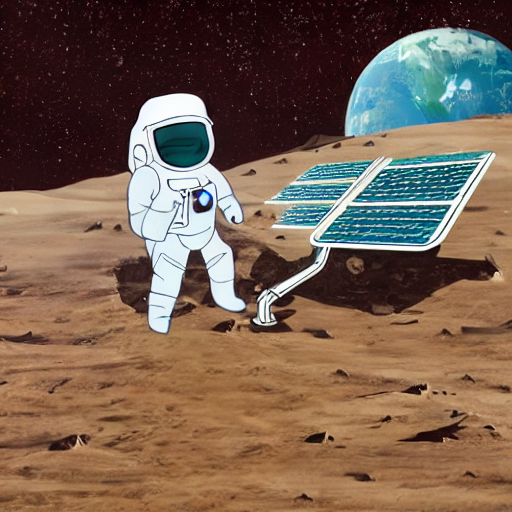

### **Load Model Inpainting**

In [31]:
from diffusers import StableDiffusionInpaintPipeline

# Free the text-to-image pipeline first: a T4 has ~15 GB and we still need room for CLIPSeg and SDXL later.
try :
  del pipe
  clear_memory()
  print("pipe sudah bersih")
except :
  print("pipe tidak perlu dibersihkan / belom ada")


pipe tidak perlu dibersihkan / belom ada


In [32]:
from diffusers import StableDiffusionInpaintPipeline

INPAINT_MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-inpainting"
inpaint_pipe = StableDiffusionInpaintPipeline.from_pretrained(
    INPAINT_MODEL_ID, torch_dtype=DTYPE, use_safetensors=False
).to(DEVICE)
inpaint_pipe.enable_attention_slicing()
print("Inpainting pipeline ready. VRAM used: %.2f GB" % (torch.cuda.memory_allocated() / 1e9))

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Inpainting pipeline ready. VRAM used: 2.78 GB


### **Manual Masking**

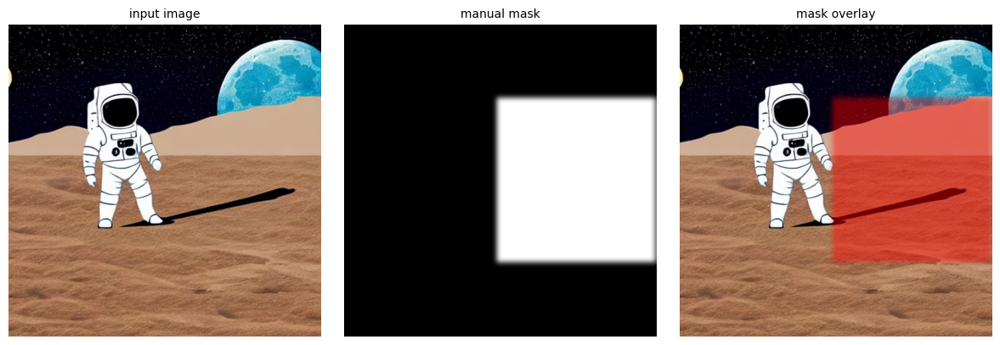

In [42]:
# Input = the image from generate_advanced_image(), NOT a new generation.
init_image = image_advanced.convert("RGB").resize((512, 512))

# The mask is a single-channel ("L") image of the same size as the input:
#   255 (white) = pixels to REPAINT      0 (black) = pixels to KEEP
# As an array it has shape (H, W) = (512, 512), indexed as mask[y, x].
mask_array = np.zeros((512, 512), dtype=np.uint8)      # start with "keep everything"

# Rectangle to the right of the astronaut where the broken satellite should appear.
x0, x1 = 250, 510      # columns (horizontal range)
y0, y1 = 120, 390      # rows    (vertical range)
mask_array[y0:y1, x0:x1] = 255                         # numpy slicing is [rows, cols]

mask_image = Image.fromarray(mask_array)
# A light blur feathers the border so the repainted region blends into its surroundings.
mask_image = mask_image.filter(ImageFilter.GaussianBlur(radius=4))

# Visual check: overlay the mask in red on top of the image.
overlay = init_image.copy()
red = Image.new("RGB", init_image.size, (255, 0, 0))
overlay = Image.composite(red, overlay, mask_image.point(lambda v: int(v * 0.45)))   # 45% opacity

show_images([init_image, mask_image.convert("RGB"), overlay], ["input image", "manual mask", "mask overlay"])

### **Generate**

  0%|          | 0/40 [00:00<?, ?it/s]

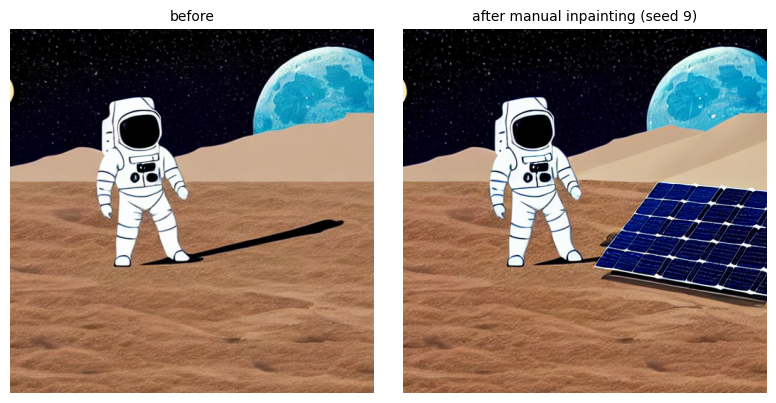

In [43]:
INPAINT_PROMPT = ("a broken satellite with damaged solar panels lying on the moon surface, "
                  "2D digital art, flat vector style, detailed, cast shadow")
INPAINT_NEGATIVE = "photo, blurry, low quality, deformed, text, watermark, extra astronaut"

generator = torch.Generator(device=DEVICE).manual_seed(9)      # seed required by the task
with torch.inference_mode():
    inpainted_manual = inpaint_pipe(
        prompt=INPAINT_PROMPT,
        negative_prompt=INPAINT_NEGATIVE,
        image=init_image,
        mask_image=mask_image,
        num_inference_steps=40,
        guidance_scale=20,
        strength=1.0,          # 1.0 = fully regenerate the masked area (needed to create a new object)
        generator=generator,
    ).images[0]

inpainted_manual.save("outputs/07_inpaint_manual.png")
show_images([init_image, inpainted_manual], ["before", "after manual inpainting (seed 9)"])

## **Inpainting Menggunakan Automasking**

Anda bebas untuk melakukan inpainting di area manapun menggunakan model segmentation. Terapkan inpainting pada gambar hasil inpainting manual di level basic sebelumnya.

### **load Model Segmentation Untuk Masking**

In [44]:
from transformers import CLIPSegProcessor, CLIPSegForImageSegmentation

# CLIPSeg segments from a TEXT description ("the astronaut"), so no clicks or boxes are needed.
seg_processor = CLIPSegProcessor.from_pretrained("CIDAS/clipseg-rd64-refined")
seg_model = CLIPSegForImageSegmentation.from_pretrained("CIDAS/clipseg-rd64-refined").to(DEVICE).eval()
print("CLIPSeg loaded. VRAM used: %.2f GB" % (torch.cuda.memory_allocated() / 1e9))

Loading weights:   0%|          | 0/462 [00:00<?, ?it/s]

CLIPSeg loaded. VRAM used: 3.38 GB


### **Masking with Segmentation Model**

Mask covers 18.6% of the image


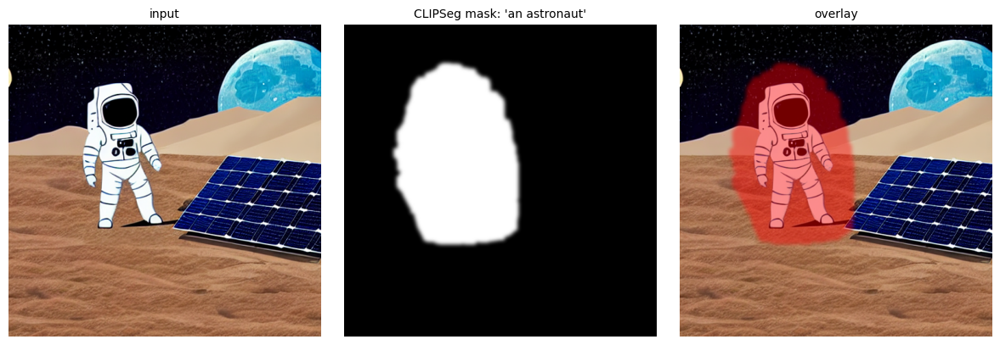

In [57]:
# Input = result of the manual inpainting step.
auto_input = inpainted_manual.convert("RGB")
SEGMENT_TEXT = "an astronaut"        # change this to segment anything else you want to edit
THRESHOLD = 0.005                      # probability cut-off for "belongs to the object"

inputs = seg_processor(text=[SEGMENT_TEXT], images=[auto_input], return_tensors="pt", padding=True).to(DEVICE)
with torch.inference_mode():
    logits = seg_model(**inputs).logits          # shape [352, 352]: low-res raw scores, not probabilities

# 1) logits -> probabilities in [0, 1]
probs = torch.sigmoid(logits)
# 2) add batch + channel dims -> [1, 1, 352, 352], because interpolate() expects NCHW
probs = probs.reshape(1, 1, *probs.shape[-2:])
# 3) upsample to the image resolution (512 x 512); bilinear keeps the edges smooth
probs = torch.nn.functional.interpolate(probs.float(), size=auto_input.size[::-1], mode="bilinear", align_corners=False)
# 4) binarise: True where the model is confident, then scale to 0/255 for PIL
binary = (probs[0, 0] > THRESHOLD).cpu().numpy().astype(np.uint8) * 255

auto_mask = Image.fromarray(binary)
# 5) dilate: MaxFilter(size) takes the max in a size x size window, growing the white area by ~size//2 px
#    so the mask fully covers the object edges/halo. Then blur to feather the border.
auto_mask = auto_mask.filter(ImageFilter.MaxFilter(15)).filter(ImageFilter.GaussianBlur(3))

coverage = (np.array(auto_mask) > 127).mean() * 100
print(f"Mask covers {coverage:.1f}% of the image")

overlay = Image.composite(Image.new("RGB", auto_input.size, (255, 0, 0)), auto_input,
                          auto_mask.point(lambda v: int(v * 0.45)))
show_images([auto_input, auto_mask.convert("RGB"), overlay], ["input", f"CLIPSeg mask: '{SEGMENT_TEXT}'", "overlay"])

### **Generate**

  0%|          | 0/40 [00:00<?, ?it/s]

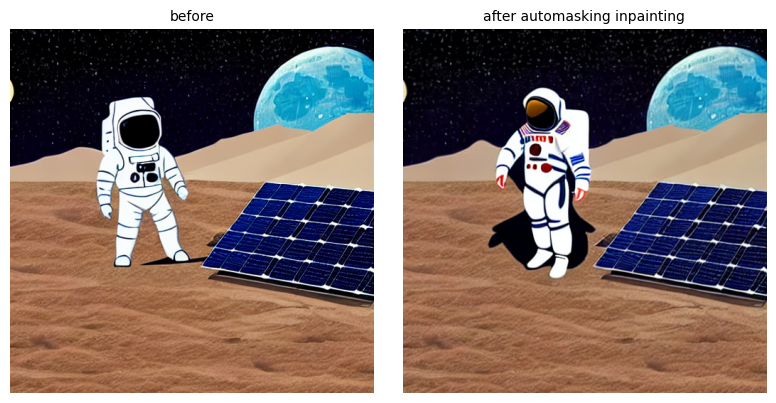

In [61]:
AUTO_PROMPT = ("an astronaut in a clean white spacesuit holding a american flag, "
               "2D digital art, flat vector style, detailed")
AUTO_NEGATIVE = "photo, blurry, low quality, deformed, extra limbs, text, watermark"

generator = torch.Generator(device=DEVICE).manual_seed(9)
with torch.inference_mode():
    inpainted_auto = inpaint_pipe(
        prompt=AUTO_PROMPT,
        negative_prompt=AUTO_NEGATIVE,
        image=auto_input,
        mask_image=auto_mask,
        num_inference_steps=40,
        guidance_scale=18.0,
        strength=1.0,
        generator=generator,
    ).images[0]

inpainted_auto.save("outputs/08_inpaint_auto.png")
show_images([auto_input, inpainted_auto], ["before", "after automasking inpainting"])

In [62]:
# CLIPSeg is no longer needed.
del seg_model, seg_processor, inputs, logits, probs
clear_memory()

## **Outpainting**

**Perhatian:** Gunakan gambar hasil inpainting (manual atau otomatis) sebagai input pada tahap ini.

Pastikan outpainting yang dilakukan mendekati gambar yang diharapkan di bawah ini dan terlihat natural dan masih berhubungan dengan gambar dasar.

###**Referensi Expected Output:**

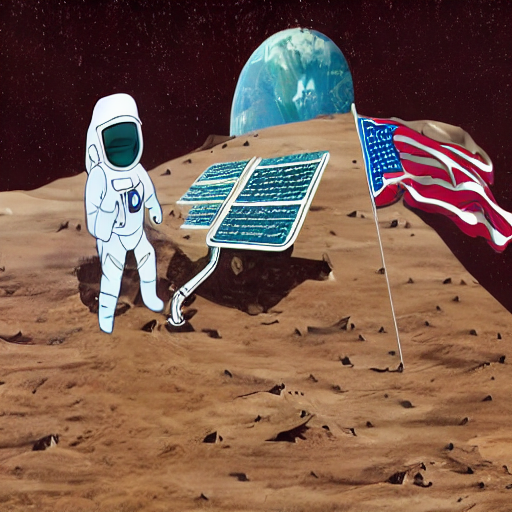

### **Prepare the Canvas**

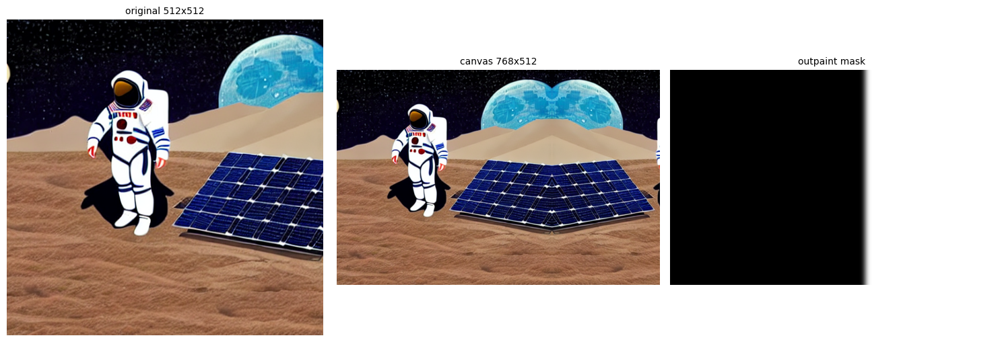

In [64]:
# Input = the inpainted image (auto result; swap for `inpainted_manual` if you prefer).
src = inpainted_auto.convert("RGB")
W, H = src.size                     # 512 x 512
EXTEND_RIGHT = 256                  # new pixels to add on the right (keep a multiple of 8)
OVERLAP = 48                        # strip of the original that is re-painted so the seam blends

new_W = W + EXTEND_RIGHT            # 768
src_arr = np.array(src)             # shape (H, W, 3), dtype uint8

# --- Canvas: pad the array on the right. np.pad pad_width = ((top, bottom), (left, right), (channels)).
# 'reflect' mirrors the last columns into the new area, which gives the model plausible colours/texture
# to continue from (a flat grey fill makes the seam much more visible).
canvas_arr = np.pad(src_arr, ((0, 0), (0, EXTEND_RIGHT), (0, 0)), mode="reflect")   # (512, 768, 3)
canvas = Image.fromarray(canvas_arr)

# --- Mask, shape (H, new_W): 255 = repaint.
# Columns [W - OVERLAP, new_W) are repainted: the whole new area + a thin overlap inside the original.
mask_arr = np.zeros((H, new_W), dtype=np.uint8)
mask_arr[:, W - OVERLAP:] = 255
outpaint_mask = Image.fromarray(mask_arr).filter(ImageFilter.GaussianBlur(6))   # soften the seam

show_images([src, canvas, outpaint_mask.convert("RGB")], ["original 512x512", f"canvas {new_W}x{H}", "outpaint mask"],
            figsize_per_img=5)

### **Generate**

  0%|          | 0/40 [00:00<?, ?it/s]

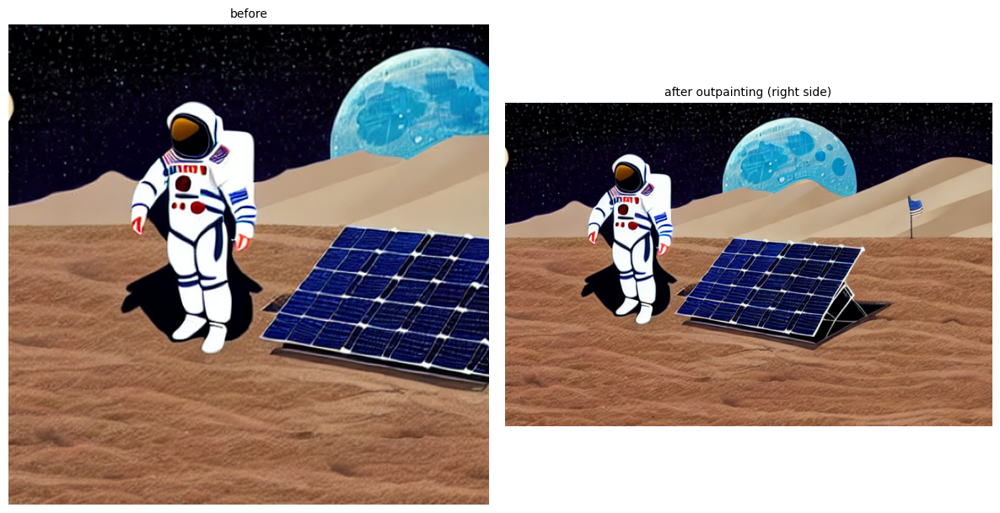

In [68]:
OUT_PROMPT = ("an american flag planted in the lunar ground on the right side, a rocky moon hill, "
              "starry black sky, planet earth, 2D digital art, flat vector style, consistent with the scene")
OUT_NEGATIVE = "photo, blurry, low quality, deformed, text, watermark, seam, border, duplicate astronaut"

generator = torch.Generator(device=DEVICE).manual_seed(9)
with torch.inference_mode():
    outpainted = inpaint_pipe(
        prompt=OUT_PROMPT,
        negative_prompt=OUT_NEGATIVE,
        image=canvas,
        mask_image=outpaint_mask,
        width=new_W, height=H,            # must match the canvas, otherwise the pipeline resizes it
        num_inference_steps=40,
        guidance_scale=19.0,
        strength=1.0,
        generator=generator,
    ).images[0]

outpainted.save("outputs/09_outpaint.png")
show_images([src, outpainted], ["before", "after outpainting (right side)"], figsize_per_img=6)

## **Outpainting Zoom Out**

**Perhatian:** Gunakan gambar hasil outpainting sebelumnya sebagai input pada tahap ini.

Pada tahap ini Anda tidak diharuskan untuk meniru spesifik satu gambar saja, tetapi berikut beberapa output yang dapat dijadikan referensi.

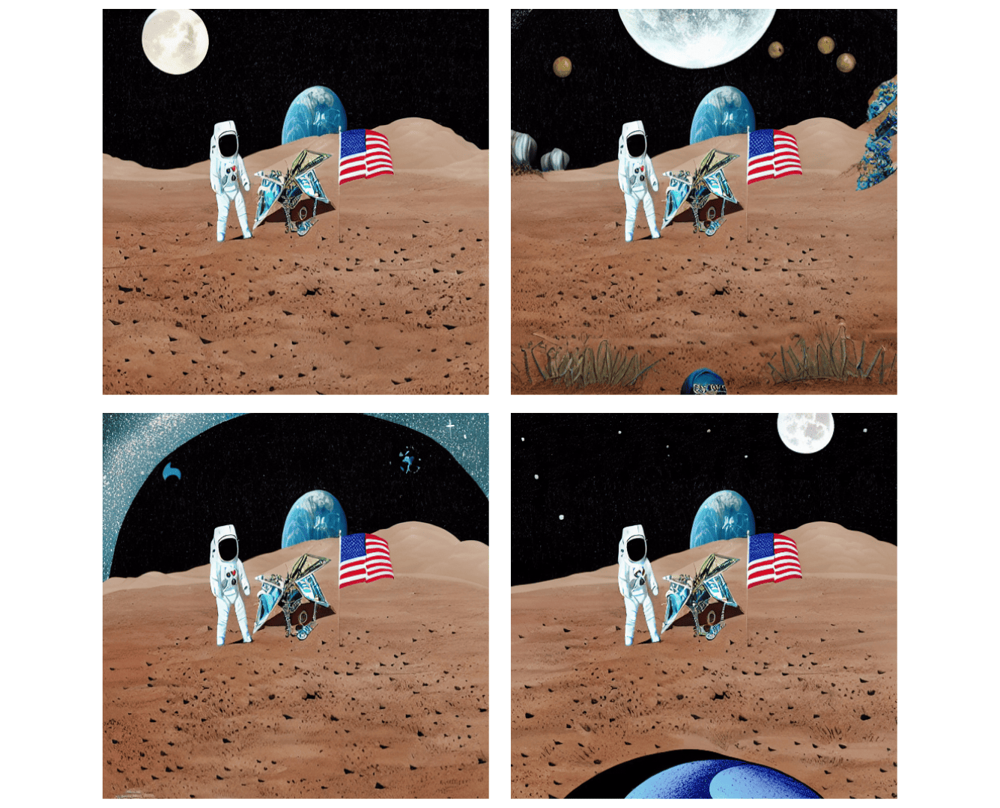

### **Prepare Canvas for Zoom Out**

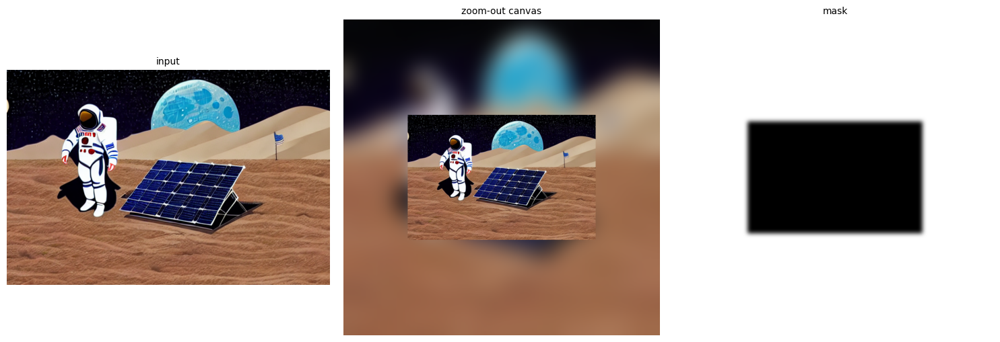

In [69]:
# Input = the outpainted image. Zoom out = shrink it and let the model invent everything AROUND it.
zo_src = outpainted.convert("RGB")
ZO_W, ZO_H = 768, 768                # final canvas size (multiples of 8)
SCALE = 0.6                          # the original occupies 60% of the canvas width
INNER_OVERLAP = 16                   # px of the pasted image that are repainted to hide the border

sw, sh = zo_src.size
new_w = int(sw * SCALE) // 8 * 8
new_h = int(sh * SCALE) // 8 * 8
small = zo_src.resize((new_w, new_h), Image.LANCZOS)

# Top-left corner that centres the shrunken image on the canvas.
ox, oy = (ZO_W - new_w) // 2, (ZO_H - new_h) // 2

# Background: a heavily blurred, stretched copy of the original, so the empty area already has
# roughly the right colours (sky at the top, ground at the bottom) for the model to refine.
zo_canvas = zo_src.resize((ZO_W, ZO_H), Image.LANCZOS).filter(ImageFilter.GaussianBlur(25))
zo_canvas.paste(small, (ox, oy))

# Mask, shape (ZO_H, ZO_W): start with 255 everywhere (repaint all), then punch a 0 "keep" window
# over the pasted image, shrunk by INNER_OVERLAP px on every side so the border gets blended.
zo_mask_arr = np.full((ZO_H, ZO_W), 255, dtype=np.uint8)
zo_mask_arr[oy + INNER_OVERLAP: oy + new_h - INNER_OVERLAP,
            ox + INNER_OVERLAP: ox + new_w - INNER_OVERLAP] = 0
zo_mask = Image.fromarray(zo_mask_arr).filter(ImageFilter.GaussianBlur(5))

show_images([zo_src, zo_canvas, zo_mask.convert("RGB")], ["input", "zoom-out canvas", "mask"], figsize_per_img=5)

### **Generate**

  0%|          | 0/40 [00:00<?, ?it/s]

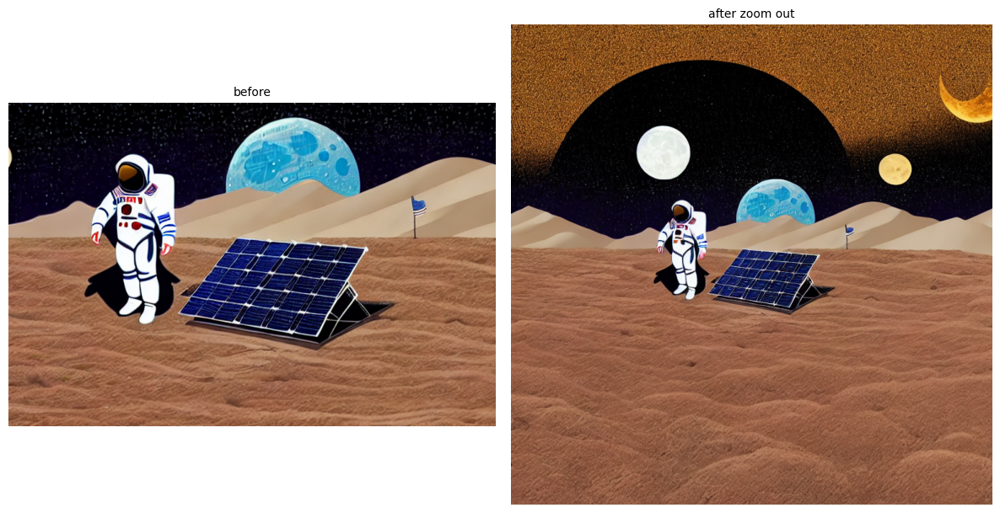

In [70]:
ZO_PROMPT = ("wide shot of a moon landing site, vast black starry sky with a bright full moon and distant planets, "
             "rocky lunar plains with small craters in the foreground, 2D digital art, flat vector style")
ZO_NEGATIVE = "photo, blurry, low quality, deformed, text, watermark, border, frame, seam"

generator = torch.Generator(device=DEVICE).manual_seed(9)
with torch.inference_mode():
    zoomed_out = inpaint_pipe(
        prompt=ZO_PROMPT,
        negative_prompt=ZO_NEGATIVE,
        image=zo_canvas,
        mask_image=zo_mask,
        width=ZO_W, height=ZO_H,
        num_inference_steps=40,
        guidance_scale=8.0,
        strength=1.0,
        generator=generator,
    ).images[0]

zoomed_out.save("outputs/10_zoom_out.png")
show_images([zo_src, zoomed_out], ["before", "after zoom out"], figsize_per_img=6)

In [72]:
# Done with the SD 1.5 inpainting model: free VRAM before loading SDXL.
try:
    del inpaint_pipe
    clear_memory()
except:
    pass

## **Base + Refiner Image Generation**